# Sample4Geo — Disaster-specific similarity evaluation

**Evaluation only.** Uses the original Sample4Geo model/weights, input transforms, and test directories.

**Six similarity matrices per enabled model** are produced:

| Figure | Ground photographs | Satellite candidates | Desired behavior |
|---|---|---|---|
| Flood — Positive | `Test_ground_image/Flood/` | Satellite names starting `FLOOD` / `FLOODING` | Higher similarity is better |
| Tsunami — Positive | `Test_ground_image/Tsunami/` | Satellite names starting `TSUNAMI` | Higher similarity is better |
| Cyclone — Positive | `Test_ground_image/Cyclone/` | Satellite names starting `GABRIELLE_HAWKESBAY` / `CYCLONE` | Higher similarity is better |
| Easy Negative | `Test_ground_image/easy_negative/` | First 2 alphabetically from EACH disaster category (6 total) | Lower similarity is better |
| Random Negative | `Test_ground_image/random_negative/` | Same first 2 × 3 category selection (6 total) | Lower similarity is better |
| Hard Negative | **Tsunami ground photos** from `Tsunami/` | Cyclone satellite photos only | Lower similarity is better |

The older `Test_ground_image/positive/` and unrelated folders are **intentionally ignored**.

**Metrics:** FPR percentages for the three negatives; positive threshold acceptance rate for each disaster; and optional **filename-verified** positive confusion matrices and precision. Disaster-category agreement alone does **not** establish that a particular ground photograph depicts a particular satellite location. Filename-based precision is calculated only for ground queries that have at least one identifiable matching satellite; unmatched queries are flagged rather than silently labeled as negatives.

Threshold is `cosine > 0.50`. This is a chosen operating threshold, **not** a calibrated probability.

# 1. Configuration — model selection, folders, categories

In [1]:
from pathlib import Path
import re
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, Normalize
from PIL import Image
from IPython.display import display

import torch
import torch.nn.functional as F

REPO_ROOT = Path(r"E:\python_project\Geo\Sample4Geo")
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from sample4geo.model import TimmModel
from sample4geo.transforms import get_transforms_val

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
USE_AMP = torch.cuda.is_available()
MODEL_NAME = "convnext_base.fb_in22k_ft_in1k_384"
SATELLITE_SIZE = (384, 384)
GROUND_SIZE = (384, 384)
INFERENCE_BATCH_SIZE = 16
COSINE_THRESHOLD = 0.50

GROUND_ROOT = Path(r"E:\python_project\Geo\Test_ground_image")
SATELLITE_FOLDER = Path(r"E:\python_project\Geo\Test_sat_image")

# Satellite names are recognized by their leading prefix.
# Extend prefixes if you add new imagery or naming conventions.
SATELLITE_CATEGORY_PREFIXES = {
    "Flood": ("FLOOD", "FLOODING"),
    "Tsunami": ("TSUNAMI",),
    "Cyclone": ("GABRIELLE_HAWKESBAY", "GABRIELE_HAWKESBAY", "CYCLONE"),
}

POSITIVE_CATEGORIES = ["Flood", "Tsunami", "Cyclone"]
NEGATIVE_TYPES = ["Easy Negative", "Random Negative", "Hard Negative"]
FIGURE_ORDER = POSITIVE_CATEGORIES + NEGATIVE_TYPES

NEGATIVE_SATELLITES_PER_CATEGORY = 2

# User requested: Hard Negative = Tsunami GROUND vs Cyclone SATELLITES.
# Set to "hard_negative" instead if you specifically want the files
# inside the old hard_negative folder to be the ground queries.
HARD_NEGATIVE_GROUND_SOURCE = "Tsunami"

MODEL_REGISTRY = {
    "baseline": {
        "label": "Baseline",
        "checkpoint": REPO_ROOT / "pretrained" / "cvusa" / MODEL_NAME / "weights_e40_98.6830.pth",
    },
    "panorama": {
        "label": "Panorama",
        "checkpoint": REPO_ROOT / "FT" / "CVIAN_panorama_run01" / "best_model.pth",
    },
    "panorama_contrastive": {
        "label": "Panorama with Contrastive Learning",
        "checkpoint": REPO_ROOT / "FT" / "Andrew" / "andrew_panoroma.pth",
    },
}

# ============================================================
# EDIT HERE TO SELECT THE MODEL(S)
# "baseline", "panorama", "panorama_contrastive"
# ============================================================
ACTIVE_MODEL_KEYS = ["panorama"]

SAVE_FIGURES = False
FIGURE_OUTPUT_DIR = REPO_ROOT / "FT" / "disaster_category_evaluation"
if SAVE_FIGURES:
    FIGURE_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Python:", sys.executable)
print("Device:", DEVICE)
print("Model selection:", ACTIVE_MODEL_KEYS)
print("Threshold: cosine >", COSINE_THRESHOLD)
print("Hard Negative ground source:", HARD_NEGATIVE_GROUND_SOURCE)

E:\python_project\Geo\Sample4Geo\Geo761\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python: E:\python_project\Geo\Sample4Geo\Geo761\Scripts\python.exe
Device: cuda
Model selection: ['panorama']
Threshold: cosine > 0.5
Hard Negative ground source: Tsunami


# 2. Load selected pretrained or fine-tuned weights

In [2]:
def extract_state_dict(checkpoint):

    if not isinstance(checkpoint, dict):
        raise TypeError("Checkpoint is not a valid PyTorch object.")

    if "state_dict" in checkpoint:
        state_dict = checkpoint["state_dict"]
    elif "model_state_dict" in checkpoint:
        state_dict = checkpoint["model_state_dict"]
    elif "model" in checkpoint and isinstance(checkpoint["model"], dict):
        state_dict = checkpoint["model"]
    else:
        state_dict = checkpoint

    cleaned = {}

    for key, value in state_dict.items():
        if key.startswith("module."):
            key = key[len("module."):]
        cleaned[key] = value

    return cleaned



def load_sample4geo_model(checkpoint_path):

    checkpoint_path = Path(checkpoint_path)

    if not checkpoint_path.exists():
        raise FileNotFoundError(f"Checkpoint not found: {checkpoint_path}")

    model = TimmModel(
        MODEL_NAME,
        pretrained=False,
        img_size=384,
    )

    checkpoint = torch.load(checkpoint_path, map_location="cpu")
    state_dict = extract_state_dict(checkpoint)

    model.load_state_dict(state_dict, strict=True)
    model = model.to(DEVICE)
    model.eval()

    return model



def load_selected_models(model_keys):

    selected_models = {}

    for model_key in model_keys:
        if model_key not in MODEL_REGISTRY:
            raise KeyError(f"Unknown model key: {model_key}")

        model_label = MODEL_REGISTRY[model_key]["label"]
        checkpoint_path = MODEL_REGISTRY[model_key]["checkpoint"]

        print("Loading model:", model_label)
        print("Checkpoint:", checkpoint_path)

        selected_models[model_key] = load_sample4geo_model(checkpoint_path)

    print()
    print("Loaded model count:", len(selected_models))

    return selected_models

# 3. Load selected models and matching preprocessing

In [3]:
models = load_selected_models(ACTIVE_MODEL_KEYS)

reference_model_key = ACTIVE_MODEL_KEYS[0]
reference_model = models[reference_model_key]
reference_config = reference_model.get_config()

MEAN = reference_config["mean"]
STD = reference_config["std"]

sat_transform, ground_transform = get_transforms_val(
    SATELLITE_SIZE,
    GROUND_SIZE,
    mean=MEAN,
    std=STD,
)

print("Reference model for preprocessing:", MODEL_REGISTRY[reference_model_key]["label"])
print("Mean:", MEAN)
print("Std:", STD)

Loading model: Panorama
Checkpoint: E:\python_project\Geo\Sample4Geo\FT\CVIAN_panorama_run01\best_model.pth

Loaded model count: 1
Reference model for preprocessing: Panorama
Mean: (0.485, 0.456, 0.406)
Std: (0.229, 0.224, 0.225)


# 4. Discover disaster folders and categorize satellite images

All satellites remain in **one satellite folder**. Prefix-based grouping picks the correct set for each disaster. The two-satellite subset used for Easy and Random Negative is selected by **case-insensitive alphabetical filename order** within each category.

In [4]:
VALID_SUFFIXES = {".png", ".jpg", ".jpeg", ".tif", ".tiff", ".webp"}


def find_images(folder, recursive=False):
    if not folder.is_dir():
        return []
    files = folder.rglob("*") if recursive else folder.iterdir()
    return sorted(
        [p for p in files if p.is_file() and p.suffix.lower() in VALID_SUFFIXES],
        key=lambda p: (p.name.casefold(), str(p).casefold()),
    )


def normalized_name(filename):
    """Remove separator/case differences, leaving letters and numbers."""
    return re.sub(r"[^A-Z0-9]", "", Path(filename).stem.upper())


def assign_satellite_category(path):
    stem = normalized_name(path.name)
    matches = [
        cat for cat, prefixes in SATELLITE_CATEGORY_PREFIXES.items()
        if any(stem.startswith(normalized_name(prefix)) for prefix in prefixes)
    ]
    if len(matches) > 1:
        raise ValueError(f"Ambiguous satellite category for {path.name}: {matches}")
    return matches[0] if matches else None


satellite_files = find_images(SATELLITE_FOLDER)
if not satellite_files:
    raise FileNotFoundError(f"No satellite images found in {SATELLITE_FOLDER}")

satellite_by_category = {
    cat: [] for cat in POSITIVE_CATEGORIES
}
unknown_satellites = []
for path in satellite_files:
    cat = assign_satellite_category(path)
    if cat is None:
        unknown_satellites.append(path)
    else:
        satellite_by_category[cat].append(path)

# Sorting occurs alphabetically before selecting negative subsets.
negative_satellites = []
for cat in POSITIVE_CATEGORIES:
    group = satellite_by_category[cat]
    if len(group) < NEGATIVE_SATELLITES_PER_CATEGORY:
        raise ValueError(
            f"Need {NEGATIVE_SATELLITES_PER_CATEGORY} {cat} satellites, "
            f"but found {len(group)}. Check SATELLITE_CATEGORY_PREFIXES."
        )
    negative_satellites.extend(group[:NEGATIVE_SATELLITES_PER_CATEGORY])

positive_ground_paths = {
    cat: find_images(GROUND_ROOT / cat, recursive=True)
    for cat in POSITIVE_CATEGORIES
}

for cat in POSITIVE_CATEGORIES:
    if not positive_ground_paths[cat]:
        raise FileNotFoundError(f"No {cat} ground photos found under {GROUND_ROOT / cat}")
    if not satellite_by_category[cat]:
        raise ValueError(f"No {cat} satellite candidates found")

negative_ground_paths = {
    "Easy Negative": find_images(GROUND_ROOT / "easy_negative", recursive=True),
    "Random Negative": find_images(GROUND_ROOT / "random_negative", recursive=True),
    "Hard Negative": find_images(GROUND_ROOT / HARD_NEGATIVE_GROUND_SOURCE, recursive=True),
}

for name, paths in negative_ground_paths.items():
    if not paths:
        raise FileNotFoundError(f"No ground photos found for {name}")

# These six comparisons are the *only* pair groups for inference.
# Ground and satellite filenames are maintained exactly as provided.
EVALUATION_GROUPS = {
    cat: {
        "ground_paths": positive_ground_paths[cat],
        "satellite_paths": satellite_by_category[cat],
        "is_positive": True,
    }
    for cat in POSITIVE_CATEGORIES
}
EVALUATION_GROUPS["Easy Negative"] = {
    "ground_paths": negative_ground_paths["Easy Negative"],
    "satellite_paths": negative_satellites,
    "is_positive": False,
}
EVALUATION_GROUPS["Random Negative"] = {
    "ground_paths": negative_ground_paths["Random Negative"],
    "satellite_paths": negative_satellites,
    "is_positive": False,
}
EVALUATION_GROUPS["Hard Negative"] = {
    "ground_paths": negative_ground_paths["Hard Negative"],
    "satellite_paths": satellite_by_category["Cyclone"],
    "is_positive": False,
}

print("DISASTER-SPECIFIC SATELLITE INVENTORY")
for category in POSITIVE_CATEGORIES:
    print()
    print(category, "satellites:", len(satellite_by_category[category]))
    for path in satellite_by_category[category]:
        print("  ", path.name)

print()
print("EASY / RANDOM NEGATIVE: FIRST 2 ALPHABETICALLY FROM EACH CATEGORY")
for category in POSITIVE_CATEGORIES:
    print(category)
    for path in satellite_by_category[category][:NEGATIVE_SATELLITES_PER_CATEGORY]:
        print("  ", path.name)

print()
print("HARD NEGATIVE: ground from", HARD_NEGATIVE_GROUND_SOURCE)
print("HARD NEGATIVE: satellites from Cyclone")

print()
print("EVALUATION GROUP COUNTS")
summary_rows = []
for group_name in FIGURE_ORDER:
    group = EVALUATION_GROUPS[group_name]
    summary_rows.append({
        "Figure": group_name,
        "Ground images": len(group["ground_paths"]),
        "Satellite images": len(group["satellite_paths"]),
        "Total pairs": len(group["ground_paths"]) * len(group["satellite_paths"]),
    })
display(pd.DataFrame(summary_rows))

if unknown_satellites:
    print()
    print("Unrecognized satellite filenames (ignored):")
    for path in unknown_satellites:
        print(" -", path.name)

DISASTER-SPECIFIC SATELLITE INVENTORY

Flood satellites: 4
   FLOODING_FLORIDA_SAT.jpeg
   FLOODING_LIBYA_SAT.jpeg
   FLOODING_LUGANVILLE_SAT.jpeg
   FLOODING_NATHAMAKI_SAT.jpeg

Tsunami satellites: 3
   TSUNAMI_NUKU'ALOFA_SAT.jpg
   TSUNAMI_PALU_SAT.jpg
   TSUNAMI_PALU_SAT2.jpg

Cyclone satellites: 5
   GABRIELLE_HAWKESBAY_SAT1.png
   GABRIELLE_HAWKESBAY_SAT2.png
   GABRIELLE_HAWKESBAY_SAT3.png
   GABRIELLE_HAWKESBAY_SAT4.png
   GABRIELLE_HAWKESBAY_SAT5.png

EASY / RANDOM NEGATIVE: FIRST 2 ALPHABETICALLY FROM EACH CATEGORY
Flood
   FLOODING_FLORIDA_SAT.jpeg
   FLOODING_LIBYA_SAT.jpeg
Tsunami
   TSUNAMI_NUKU'ALOFA_SAT.jpg
   TSUNAMI_PALU_SAT.jpg
Cyclone
   GABRIELLE_HAWKESBAY_SAT1.png
   GABRIELLE_HAWKESBAY_SAT2.png

HARD NEGATIVE: ground from Tsunami
HARD NEGATIVE: satellites from Cyclone

EVALUATION GROUP COUNTS


,Figure,Ground images,Satellite images,Total pairs
0,Flood,4,4,16
1,Tsunami,3,3,9
2,Cyclone,5,5,25
3,Easy Negative,4,6,24
4,Random Negative,4,6,24
5,Hard Negative,3,5,15



Unrecognized satellite filenames (ignored):
 - Gabrielle_Sample4Geo_Heatmap.png
 - LongBay_SAT.jpg
 - Okura_SAT.jpg
 - RodneyWard_SAT.jpg


# 5. Optional filename-based true-pair mapping for the positive confusion matrix

The matrices compare all images **within the requested disaster category**, but actual geographic correspondence is more specific. For example, a Florida flood photograph need not match a Libya flood satellite.

The helper below tries to map positive pairs by **base name** and, where present, an indexed ground suffix `_<number>` to the same `SAT<number>` satellite. Differences in spaces, underscores, and case are ignored. You can add mappings in `MANUAL_POSITIVE_MATCHES` for filenames that do not follow this rule.

**Unmatched positive ground photos are excluded from precision/confusion counts and reported separately.** Their similarity scores remain in the heatmaps and positive acceptance table. This avoids assigning false labels when filenames alone do not establish the correct location.

In [5]:
# Add exact per-image mappings here if the automatic match preview is incomplete.
# Example: "GABRIELLE_HAWKESBAY_1.png": ["GABRIELLE_HAWKESBAY_SAT1.png"]
MANUAL_POSITIVE_MATCHES = {
}


def normalize_stem(filename):
    return re.sub(r"[^A-Z0-9]+", "_", Path(filename).stem.upper()).strip("_")


def ground_match_parts(filename):
    stem = normalize_stem(filename)
    stem = re.sub(r"_(LEFT|RIGHT|CROSSV|CROSSVIEW|GROUND|IMG|IMAGE)$", "", stem)
    match = re.search(r"_(\d+)$", stem)
    if match:
        sample_num = int(match.group(1))
        stem = stem[:match.start()]
    else:
        sample_num = None
    return (re.sub(r"[^A-Z0-9]", "", stem), sample_num)


def satellite_match_parts(filename):
    stem = normalize_stem(filename)
    match = re.search(r"_(SATELLITE|SAT)(\d*)$", stem)
    if match:
        sample_num = int(match.group(2)) if match.group(2) else None
        stem = stem[:match.start()]
    else:
        sample_num = None
    return (re.sub(r"[^A-Z0-9]", "", stem), sample_num)


def infer_positive_satellites(ground_name, candidates):
    candidate_names = {p.name for p in candidates}
    if ground_name in MANUAL_POSITIVE_MATCHES:
        specified = MANUAL_POSITIVE_MATCHES[ground_name]
        missing = sorted(set(specified) - candidate_names)
        if missing:
            raise ValueError(f"Manual matches for {ground_name} not in selected satellite group: {missing}")
        return [name for name in specified if name in candidate_names]

    g_base, g_index = ground_match_parts(ground_name)
    matched = []
    for candidate in candidates:
        s_base, s_index = satellite_match_parts(candidate.name)
        if g_base == s_base and (g_index is None or g_index == s_index):
            matched.append(candidate.name)
    return matched


MATCHED_POSITIVE_SATELLITES = {}
verification_rows = []

for category in POSITIVE_CATEGORIES:
    satellites = EVALUATION_GROUPS[category]["satellite_paths"]
    for ground in EVALUATION_GROUPS[category]["ground_paths"]:
        # A pair of (category, path) keys prevents collisions from equal filenames in folders.
        pair_key = (category, str(ground))
        matches = infer_positive_satellites(ground.name, satellites)
        MATCHED_POSITIVE_SATELLITES[pair_key] = matches
        verification_rows.append({
            "Category": category,
            "Ground image": ground.name,
            "Match count": len(matches),
            "Matched satellite(s)": ", ".join(matches) if matches else "UNVERIFIED",
        })

print("POSITIVE FILENAME-BASED PAIR VERIFICATION")
match_preview = pd.DataFrame(verification_rows)
display(match_preview)
print()
print("FULL MATCH LIST (not truncated):")
for row in verification_rows:
    print(row["Category"], "|", row["Ground image"], "->", row["Matched satellite(s)"])

unverified_count = int((match_preview["Match count"] == 0).sum())
if unverified_count:
    warnings.warn(
        f"{unverified_count} positive ground photo(s) have NO verified satellite "
        "match. Similarity matrices will still include them; filename-based "
        "precision/confusion will exclude their rows. Add manual matches if available."
    )

POSITIVE FILENAME-BASED PAIR VERIFICATION


,Category,Ground image,Match count,Matched satellite(s)
0,Flood,FLOODING_FLORIDA.jpg,1,FLOODING_FLORIDA_SAT.jpeg
1,Flood,FLOODING_LIBYA.jpeg,1,FLOODING_LIBYA_SAT.jpeg
2,Flood,FLOODING_LUGANVILLE.jpeg,1,FLOODING_LUGANVILLE_SAT.jpeg
3,Flood,FLOODING_NATHAMAKI.jpg,1,FLOODING_NATHAMAKI_SAT.jpeg
4,Tsunami,TSUNAMI_NUKU'ALOFA.jpg,1,TSUNAMI_NUKU'ALOFA_SAT.jpg
5,Tsunami,TSUNAMI_PALU.jpg,2,"TSUNAMI_PALU_SAT.jpg, TSUNAMI_PALU_SAT2.jpg"
6,Tsunami,TSUNAMI_PALU2.jpeg,0,UNVERIFIED
7,Cyclone,GABRIELLE_HAWKESBAY_1.png,1,GABRIELLE_HAWKESBAY_SAT1.png
8,Cyclone,GABRIELLE_HAWKESBAY_2.PNG,1,GABRIELLE_HAWKESBAY_SAT2.png
9,Cyclone,GABRIELLE_HAWKESBAY_3.PNG,1,GABRIELLE_HAWKESBAY_SAT3.png



FULL MATCH LIST (not truncated):
Flood | FLOODING_FLORIDA.jpg -> FLOODING_FLORIDA_SAT.jpeg
Flood | FLOODING_LIBYA.jpeg -> FLOODING_LIBYA_SAT.jpeg
Flood | FLOODING_LUGANVILLE.jpeg -> FLOODING_LUGANVILLE_SAT.jpeg
Flood | FLOODING_NATHAMAKI.jpg -> FLOODING_NATHAMAKI_SAT.jpeg
Tsunami | TSUNAMI_NUKU'ALOFA.jpg -> TSUNAMI_NUKU'ALOFA_SAT.jpg
Tsunami | TSUNAMI_PALU.jpg -> TSUNAMI_PALU_SAT.jpg, TSUNAMI_PALU_SAT2.jpg
Tsunami | TSUNAMI_PALU2.jpeg -> UNVERIFIED
Cyclone | GABRIELLE_HAWKESBAY_1.png -> GABRIELLE_HAWKESBAY_SAT1.png
Cyclone | GABRIELLE_HAWKESBAY_2.PNG -> GABRIELLE_HAWKESBAY_SAT2.png
Cyclone | GABRIELLE_HAWKESBAY_3.PNG -> GABRIELLE_HAWKESBAY_SAT3.png
Cyclone | GABRIELLE_HAWKESBAY_4.png -> GABRIELLE_HAWKESBAY_SAT4.png
Cyclone | GABRIELLE_HAWKESBAY_5.png -> GABRIELLE_HAWKESBAY_SAT5.png


C:\Users\sifat\AppData\Local\Temp\ipykernel_150768\1185915337.py:79: UserWarning: 1 positive ground photo(s) have NO verified satellite match. Similarity matrices will still include them; filename-based precision/confusion will exclude their rows. Add manual matches if available.
  warnings.warn(


# 6. Run feature extraction and calculate only the requested ground–satellite comparisons

In [6]:
def embed_paths(model, paths, transform, batch_size=16):
    if not paths:
        raise ValueError("Cannot embed an empty image list")
    chunks = []
    model.eval()
    with torch.inference_mode():
        for start in range(0, len(paths), batch_size):
            image_tensors = []
            for path in paths[start:start + batch_size]:
                with Image.open(path) as image:
                    rgb = np.asarray(image.convert("RGB"))
                image_tensors.append(transform(image=rgb)["image"])
            batch = torch.stack(image_tensors).to(DEVICE, non_blocking=True)
            with torch.autocast(device_type="cuda", enabled=USE_AMP):
                features = model(batch)
            # Normalizing embeddings turns dot product into cosine similarity.
            features = F.normalize(features.float(), p=2, dim=1).cpu()
            chunks.append(features)
    return torch.cat(chunks, dim=0)


def run_model_similarity(model_key, model):
    print("Computing embeddings for:", MODEL_REGISTRY[model_key]["label"])
    all_ground = sorted(
        {path for group in EVALUATION_GROUPS.values() for path in group["ground_paths"]},
        key=lambda p: str(p).casefold(),
    )
    all_satellite = sorted(
        {path for group in EVALUATION_GROUPS.values() for path in group["satellite_paths"]},
        key=lambda p: str(p).casefold(),
    )

    ground_emb = embed_paths(model, all_ground, ground_transform, INFERENCE_BATCH_SIZE)
    sat_emb = embed_paths(model, all_satellite, sat_transform, INFERENCE_BATCH_SIZE)
    ground_index = {p: i for i, p in enumerate(all_ground)}
    sat_index = {p: j for j, p in enumerate(all_satellite)}
    scores = (ground_emb @ sat_emb.T).numpy()

    rows = []
    for group_name in FIGURE_ORDER:
        group = EVALUATION_GROUPS[group_name]
        for ground in group["ground_paths"]:
            for sat in group["satellite_paths"]:
                rows.append({
                    "model_key": model_key,
                    "model_label": MODEL_REGISTRY[model_key]["label"],
                    "query_type": group_name,
                    "ground_path": str(ground),
                    "ground_image": ground.name,
                    "satellite_image": sat.name,
                    "cosine_similarity": float(scores[ground_index[ground], sat_index[sat]]),
                    "is_positive_group": group["is_positive"],
                })
    return pd.DataFrame(rows)


all_similarity_frames = [
    run_model_similarity(model_key, models[model_key])
    for model_key in ACTIVE_MODEL_KEYS
]
similarity_raw = pd.concat(all_similarity_frames, ignore_index=True)

print()
print("Similarity inference finished.")
print("Total evaluated pairs:", len(similarity_raw))
display(similarity_raw.head())

Computing embeddings for: Panorama

Similarity inference finished.
Total evaluated pairs: 113


,model_key,model_label,query_type,ground_path,ground_image,satellite_image,cosine_similarity,is_positive_group
0,panorama,Panorama,Flood,E:\python_project\Geo\Test_ground_image\Flood\...,FLOODING_FLORIDA.jpg,FLOODING_FLORIDA_SAT.jpeg,0.382582,True
1,panorama,Panorama,Flood,E:\python_project\Geo\Test_ground_image\Flood\...,FLOODING_FLORIDA.jpg,FLOODING_LIBYA_SAT.jpeg,0.486168,True
2,panorama,Panorama,Flood,E:\python_project\Geo\Test_ground_image\Flood\...,FLOODING_FLORIDA.jpg,FLOODING_LUGANVILLE_SAT.jpeg,0.553370,True
3,panorama,Panorama,Flood,E:\python_project\Geo\Test_ground_image\Flood\...,FLOODING_FLORIDA.jpg,FLOODING_NATHAMAKI_SAT.jpeg,0.435523,True
4,panorama,Panorama,Flood,E:\python_project\Geo\Test_ground_image\Flood\...,FLOODING_LIBYA.jpeg,FLOODING_FLORIDA_SAT.jpeg,0.334159,True


# 7. Six publication-style similarity matrices per enabled model

- **Positive (Flood, Tsunami, Cyclone):** yellow → light green → green; *higher is better*.
- **Negative (Easy, Random, Hard):** light orange → orange → red; *lower is better*.
- A score **strictly greater than 0.50** is printed in **larger, bold, pure black text** in both types.
- Color scale stays fixed from −1 to +1 (the valid cosine range) across all six figures for honest visual comparisons.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


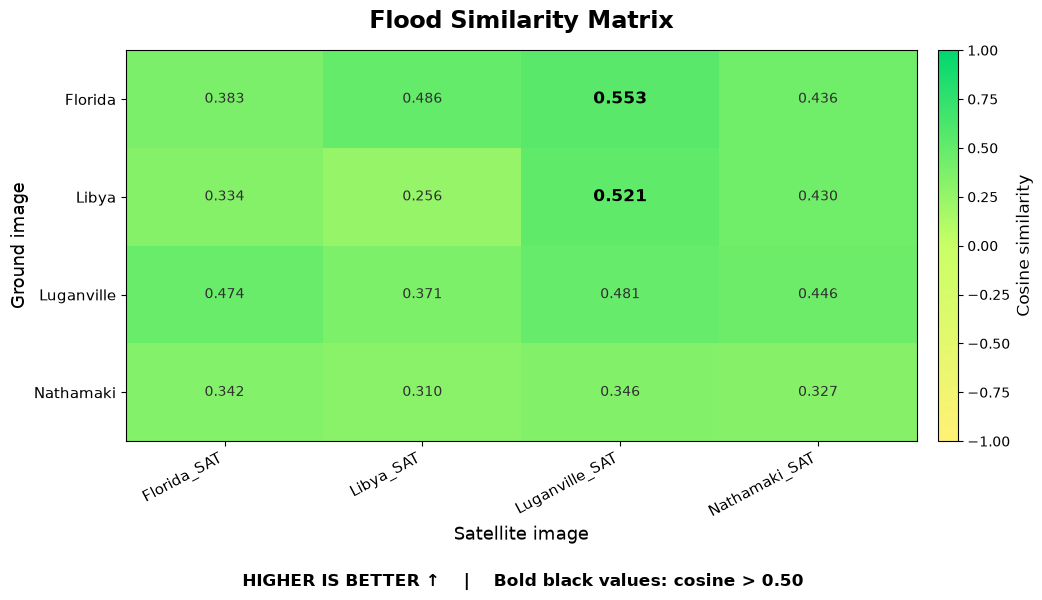

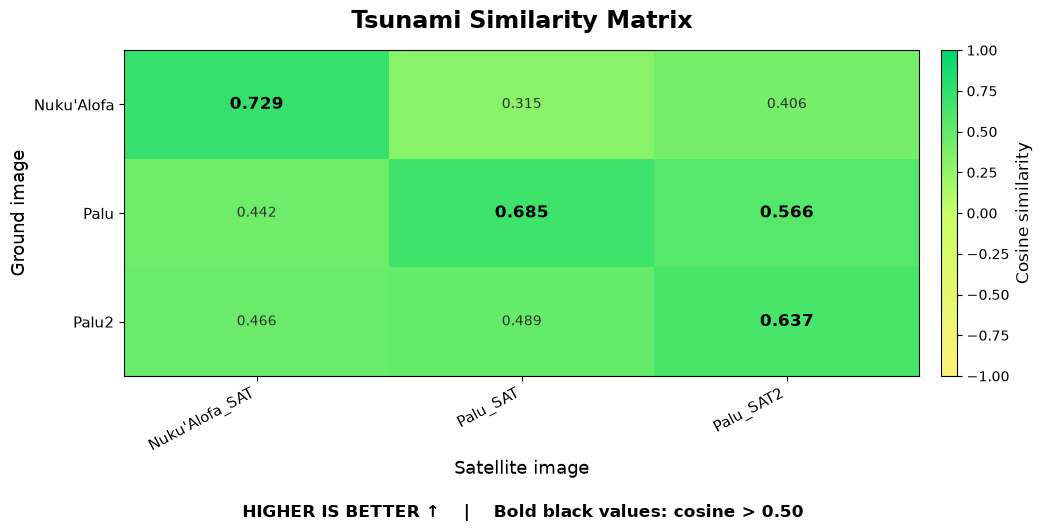

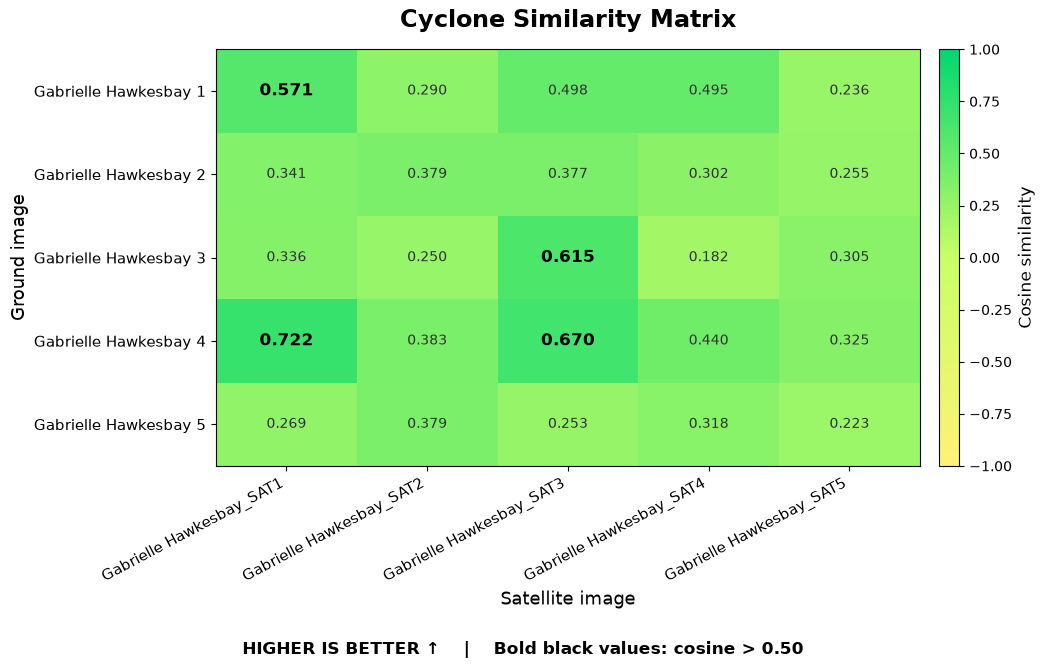

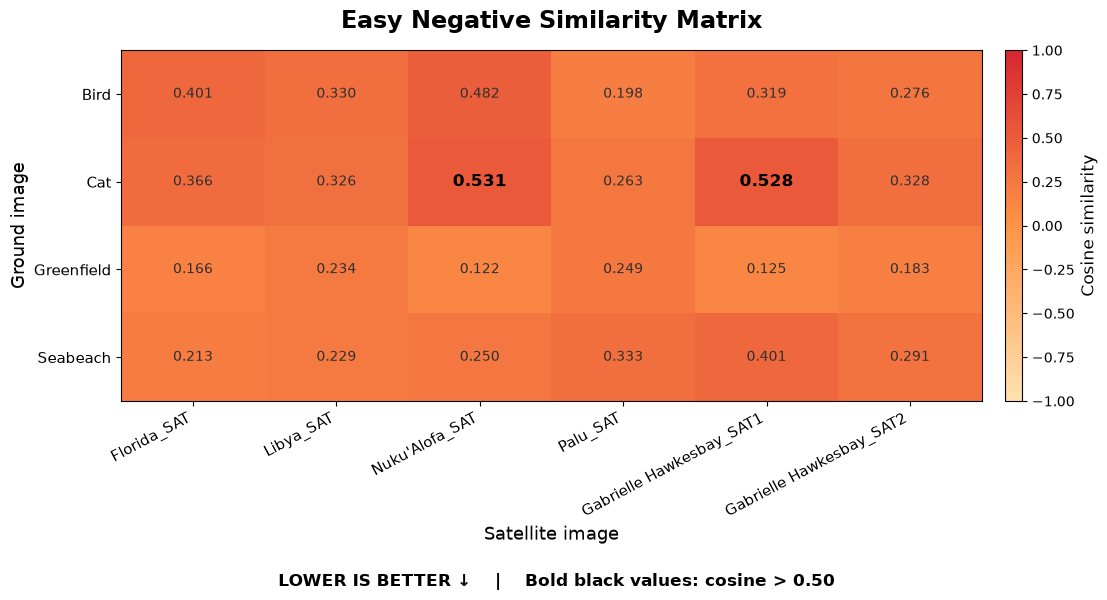

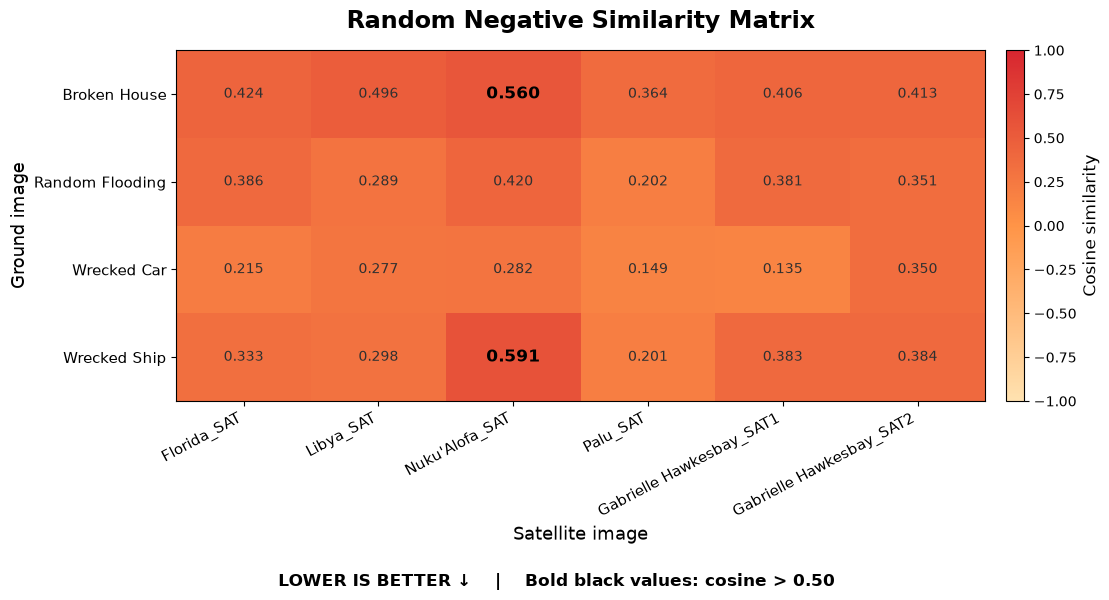

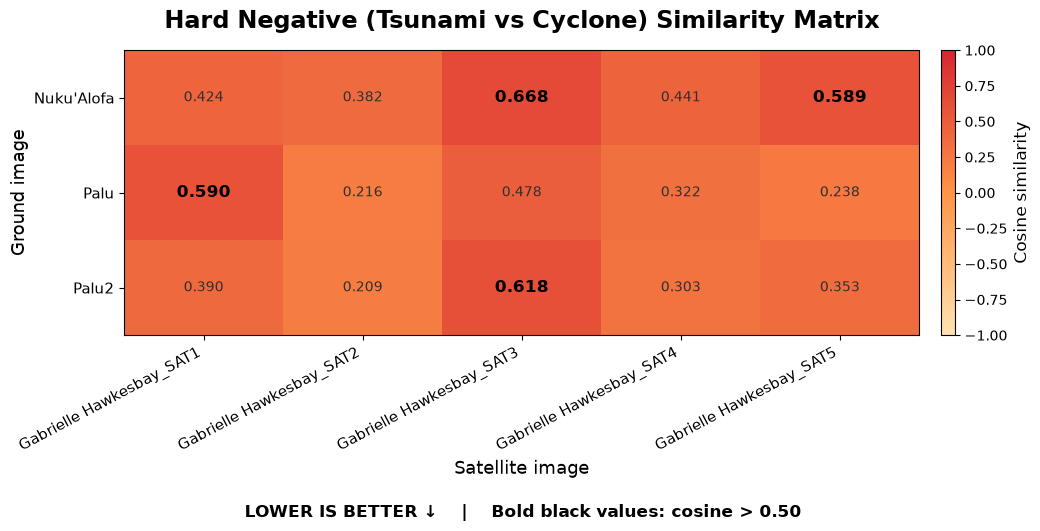

In [7]:
POSITIVE_CMAP = LinearSegmentedColormap.from_list(
    "yellow_to_green",
    ["#fff176", "#c8ff66", "#00d76f"],
)
NEGATIVE_CMAP = LinearSegmentedColormap.from_list(
    "orange_to_red",
    ["#ffe2b0", "#ff9447", "#d72630"],
)
# Fix the scale for every matrix. Warm/high scores indicate a worse negative match.
COLOR_MIN, COLOR_MAX = -1.0, 1.0


def prettify_matrix_label(filename):
    """
    Remove disaster prefixes from display labels while
    preserving the original _SAT, _SAT1, _SAT2, etc.
    """

    label = Path(filename).stem

    # Remove repeated disaster prefixes
    label = re.sub(
        r"^(FLOODING|TSUNAMI)[_\s-]+",
        "",
        label,
        flags=re.IGNORECASE
    )

    # Preserve the original satellite suffix
    match = re.search(
        r"(_SAT(?:ELLITE)?\d*)$",
        label,
        flags=re.IGNORECASE
    )

    sat_suffix = match.group(1) if match else ""

    if match:
        label = label[:match.start()]

    # Make the remaining label readable
    label = re.sub(r"[_-]+", " ", label)
    label = re.sub(r"\s+", " ", label).strip()
    label = label.title()

    return label + sat_suffix


def plot_similarity_matrix(raw_df, model_key, group_name):
    group = EVALUATION_GROUPS[group_name]
    subset = raw_df.loc[
        (raw_df["model_key"] == model_key)
        & (raw_df["query_type"] == group_name)
    ]

    # Index by full path internally (not filename) to avoid duplicates.
    pivot = subset.pivot(
        index="ground_path", columns="satellite_image", values="cosine_similarity"
    )
    expected_rows = [str(p) for p in group["ground_paths"]]
    expected_cols = [p.name for p in group["satellite_paths"]]
    values = pivot.reindex(index=expected_rows, columns=expected_cols).to_numpy(dtype=float)

    if np.isnan(values).any():
        raise ValueError(f"Missing similarity scores for {model_key} / {group_name}")

    is_positive = group["is_positive"]
    nrows, ncols = values.shape
    width = max(11, 1.20 * ncols + 4.5)
    height = max(4.5, 0.70 * nrows + 3.2)
    fig, ax = plt.subplots(figsize=(width, height))

    cmap = POSITIVE_CMAP if is_positive else NEGATIVE_CMAP
    image = ax.imshow(values, cmap=cmap, vmin=COLOR_MIN, vmax=COLOR_MAX, aspect="auto")

    row_labels = [prettify_matrix_label(p.name) for p in group["ground_paths"]]
    col_labels = [prettify_matrix_label(name) for name in expected_cols]

    ax.set_xticks(range(ncols))
    ax.set_xticklabels(col_labels, rotation=28, ha="right", fontsize=11)
    ax.set_yticks(range(nrows))
    ax.set_yticklabels(row_labels, fontsize=11)
    ax.set_xlabel("Satellite image", fontsize=13)
    ax.set_ylabel("Ground image", fontsize=13)
    figure_title = (
        "Hard Negative (Tsunami vs Cyclone) Similarity Matrix"
        if group_name == "Hard Negative"
        else f"{group_name} Similarity Matrix"
    )

    ax.set_title(
        figure_title,
        fontsize=17, pad=16, weight="semibold",
    )

    for i in range(nrows):
        for j in range(ncols):
            score = values[i, j]
            above_threshold = score > COSINE_THRESHOLD
            ax.text(
                j, i, f"{score:.3f}",
                ha="center", va="center",
                fontsize=12 if above_threshold else 10,
                weight="bold" if above_threshold else "normal",
                color="#000000" if above_threshold else "#303030",
            )

    colorbar = fig.colorbar(image, ax=ax, fraction=0.035, pad=0.025)
    colorbar.set_label("Cosine similarity", fontsize=12)

    direction_text = "HIGHER IS BETTER ↑" if is_positive else "LOWER IS BETTER ↓"
    fig.text(
        0.5, 0.005,
        f"{direction_text}    |    Bold black values: cosine > {COSINE_THRESHOLD:.2f}",
        ha="center", fontsize=12, weight="bold",
    )
    fig.tight_layout(rect=[0.02, 0.05, 0.98, 0.99])

    if SAVE_FIGURES:
        safe_name = group_name.lower().replace(" ", "_")
        fig.savefig(
            FIGURE_OUTPUT_DIR / f"{model_key}_{safe_name}_similarity_matrix.png",
            dpi=300, bbox_inches="tight",
        )
    plt.show()


for model_key in ACTIVE_MODEL_KEYS:
    for group_name in FIGURE_ORDER:
        plot_similarity_matrix(similarity_raw, model_key, group_name)



# 8. Compute threshold-based outcomes for the **selected comparisons only**

On negative groups, any score above 0.5 is an FP. On positive groups, the overall acceptance rate is computed for all same-category candidate comparisons. A full TP/FP/TN/FN confusion matrix is computed **only for ground photos with a verified corresponding satellite file**, using filename/manual mapping from Section 5.

In [8]:
def classify_selected_pairs(raw_df, threshold=0.50):
    rows = []
    for _, row in raw_df.iterrows():
        group_name = row["query_type"]
        predicted_match = bool(row["cosine_similarity"] > threshold)
        verified = False
        actual_match = None
        outcome = "ACCEPTED" if predicted_match else "REJECTED"

        if group_name in NEGATIVE_TYPES:
            verified = True
            actual_match = False
            outcome = "FP" if predicted_match else "TN"

        else:
            key = (group_name, row["ground_path"])
            known_matches = MATCHED_POSITIVE_SATELLITES[key]
            if known_matches:
                verified = True
                actual_match = row["satellite_image"] in known_matches
                if actual_match and predicted_match:
                    outcome = "TP"
                elif actual_match and not predicted_match:
                    outcome = "FN"
                elif not actual_match and predicted_match:
                    outcome = "FP"
                else:
                    outcome = "TN"
            else:
                outcome = "UNVERIFIED"

        rows.append({
            **row.to_dict(),
            "predicted_match": predicted_match,
            "verified_actual": verified,
            "actual_match": actual_match,
            "outcome": outcome,
        })
    return pd.DataFrame(rows)


classified_pairs = classify_selected_pairs(similarity_raw, COSINE_THRESHOLD)
print("Pair-level classification sample:")
display(classified_pairs.head())

Pair-level classification sample:


,model_key,model_label,query_type,ground_path,ground_image,satellite_image,cosine_similarity,is_positive_group,predicted_match,verified_actual,actual_match,outcome
0,panorama,Panorama,Flood,E:\python_project\Geo\Test_ground_image\Flood\...,FLOODING_FLORIDA.jpg,FLOODING_FLORIDA_SAT.jpeg,0.382582,True,False,True,True,FN
1,panorama,Panorama,Flood,E:\python_project\Geo\Test_ground_image\Flood\...,FLOODING_FLORIDA.jpg,FLOODING_LIBYA_SAT.jpeg,0.486168,True,False,True,False,TN
2,panorama,Panorama,Flood,E:\python_project\Geo\Test_ground_image\Flood\...,FLOODING_FLORIDA.jpg,FLOODING_LUGANVILLE_SAT.jpeg,0.553370,True,True,True,False,FP
3,panorama,Panorama,Flood,E:\python_project\Geo\Test_ground_image\Flood\...,FLOODING_FLORIDA.jpg,FLOODING_NATHAMAKI_SAT.jpeg,0.435523,True,False,True,False,TN
4,panorama,Panorama,Flood,E:\python_project\Geo\Test_ground_image\Flood\...,FLOODING_LIBYA.jpeg,FLOODING_FLORIDA_SAT.jpeg,0.334159,True,False,True,False,TN


# 9. Positive disaster-category scores

**Positive acceptance rate** is the proportion of within-category comparisons with cosine > 0.5. It is not necessarily geographic-match recall because same-disaster images can depict different locations. A filename-verified **precision/confusion matrix** is shown separately in the next section.

In [9]:
positive_summary_rows = []
for model_key in ACTIVE_MODEL_KEYS:
    for category in POSITIVE_CATEGORIES:
        subset = classified_pairs.loc[
            (classified_pairs["model_key"] == model_key)
            & (classified_pairs["query_type"] == category)
        ]
        accepted_rate = 100 * subset["predicted_match"].mean()
        verified_subset = subset.loc[subset["verified_actual"]]
        positive_summary_rows.append({
            "Model": MODEL_REGISTRY[model_key]["label"],
            "Disaster": category,
            "Category acceptance %": round(accepted_rate, 1),
            "Pair comparisons": len(subset),
            "Verified pair comparisons": len(verified_subset),
        })
positive_acceptance_summary = pd.DataFrame(positive_summary_rows)
display(positive_acceptance_summary)

,Model,Disaster,Category acceptance %,Pair comparisons,Verified pair comparisons
0,Panorama,Flood,12.5,16,16
1,Panorama,Tsunami,44.4,9,6
2,Panorama,Cyclone,16.0,25,25


# 10. Positive filename-verified confusion matrices

Only pairs with ground-truth names verified in Section 5 count toward the confusion matrix and **Precision = TP / (TP + FP)**. If none have matching filenames, precision is reported as **N/A**, not incorrectly as zero. Each enabled model gets a confusion figure and precision summary per disaster with usable verified pairs.

Verified positive-pair confusion summary:


,model_key,Model,Disaster,TP,FP,TN,FN,Precision %,Verified pairs
0,panorama,Panorama,Flood,0,2,10,4,0.0,16
1,panorama,Panorama,Tsunami,3,0,3,0,100.0,6
2,panorama,Panorama,Cyclone,2,2,18,3,50.0,25


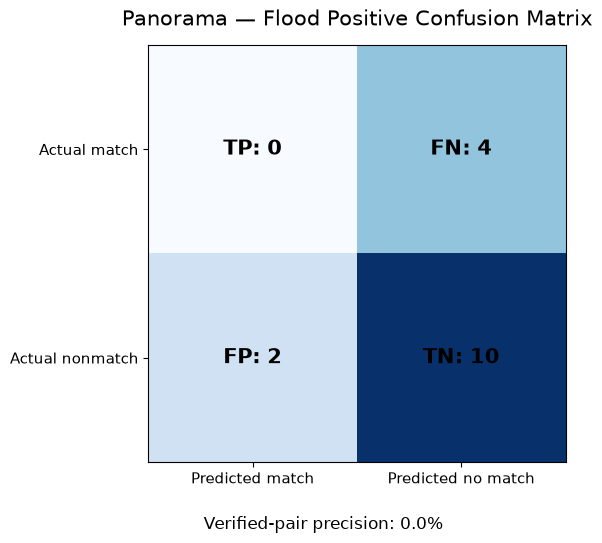

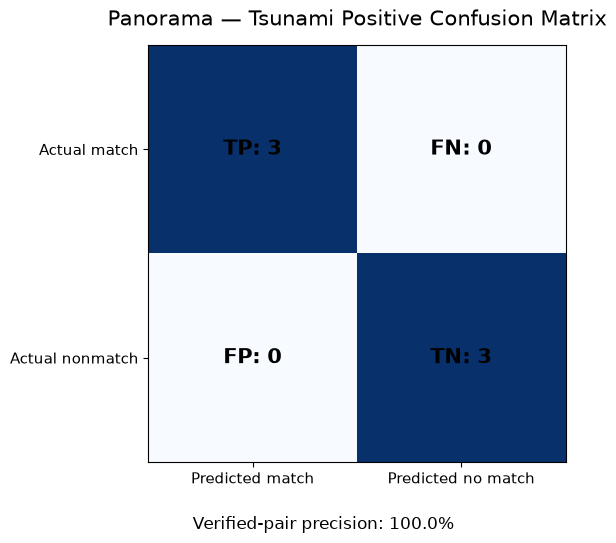

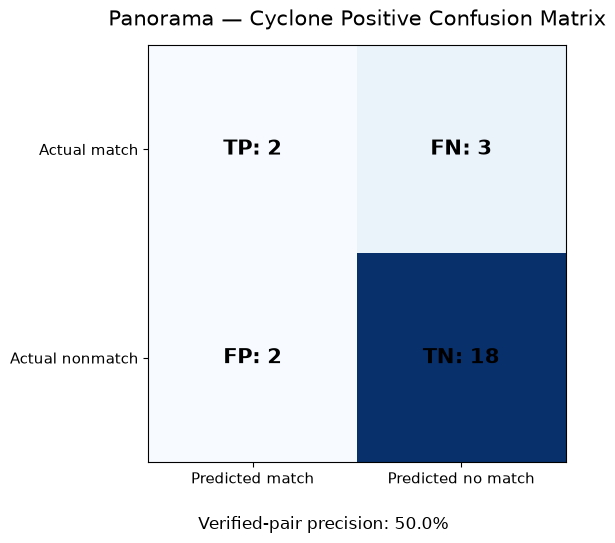

In [10]:
def summarize_filename_verified_positives(df):
    rows = []
    for model_key in ACTIVE_MODEL_KEYS:
        for category in POSITIVE_CATEGORIES:
            subset = df.loc[
                (df["model_key"] == model_key)
                & (df["query_type"] == category)
                & (df["verified_actual"])
            ]
            counts = {name: int((subset["outcome"] == name).sum())
                      for name in ["TP", "FP", "TN", "FN"]}
            denominator = counts["TP"] + counts["FP"]
            precision = 100 * counts["TP"] / denominator if denominator else np.nan
            rows.append({
                "model_key": model_key,
                "Model": MODEL_REGISTRY[model_key]["label"],
                "Disaster": category,
                **counts,
                "Precision %": precision,
                "Verified pairs": len(subset),
            })
    return pd.DataFrame(rows)


positive_confusion_summary = summarize_filename_verified_positives(classified_pairs)
print("Verified positive-pair confusion summary:")
display(positive_confusion_summary)


def plot_positive_confusion(row):
    if row["Verified pairs"] == 0:
        print("Skipping confusion figure:", row["Model"], row["Disaster"], "(no verified name matches)")
        return
    # Rows = actual match / actual nonmatch; columns = predicted match / predicted nonmatch.
    counts = np.array([[row["TP"], row["FN"]], [row["FP"], row["TN"]]], dtype=int)
    fig, ax = plt.subplots(figsize=(7.2, 5.4))
    image = ax.imshow(counts, cmap="Blues")
    ax.set_xticks([0, 1], labels=["Predicted match", "Predicted no match"], fontsize=11)
    ax.set_yticks([0, 1], labels=["Actual match", "Actual nonmatch"], fontsize=11)
    labels = [["TP", "FN"], ["FP", "TN"]]
    for i in range(2):
        for j in range(2):
            # Construct label with two calls instead of embedding a newline escape.
            ax.text(j, i, f"{labels[i][j]}: {counts[i, j]}",
                    ha="center", va="center", fontsize=15, weight="bold")
    precision_text = "N/A" if pd.isna(row["Precision %"]) else f"{row['Precision %']:.1f}%"
    ax.set_title(f"{row['Model']} — {row['Disaster']} Positive Confusion Matrix",
                 fontsize=15, pad=14)
    fig.text(0.5, 0.01, f"Verified-pair precision: {precision_text}", ha="center", fontsize=12)
    fig.tight_layout(rect=[0, 0.06, 1, 1])
    if SAVE_FIGURES:
        fig.savefig(FIGURE_OUTPUT_DIR / f"{row['model_key']}_{row['Disaster'].lower()}_positive_confusion.png",
                    dpi=300, bbox_inches="tight")
    plt.show()


for _, summary_row in positive_confusion_summary.iterrows():
    plot_positive_confusion(summary_row)

# 11. Negative-set FPR — simple percentage table

FALSE POSITIVE RATE (LOWER IS BETTER)


,Model,Type,FPR %
0,Panorama,Easy Negative,8.3%
1,Panorama,Random Negative,8.3%
2,Panorama,Hard Negative,26.7%


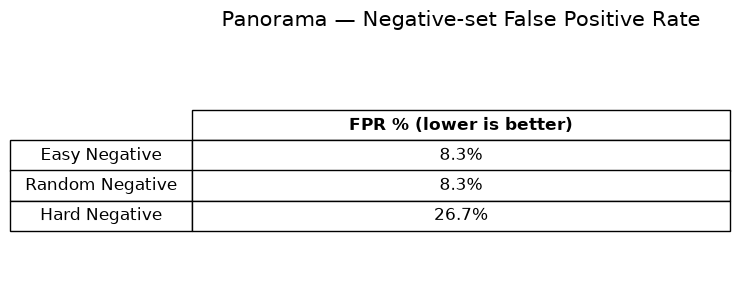

In [11]:
fpr_rows = []
for model_key in ACTIVE_MODEL_KEYS:
    for group_name in NEGATIVE_TYPES:
        subset = classified_pairs.loc[
            (classified_pairs["model_key"] == model_key)
            & (classified_pairs["query_type"] == group_name)
        ]
        fp = int((subset["outcome"] == "FP").sum())
        tn = int((subset["outcome"] == "TN").sum())
        fpr = 100 * fp / (fp + tn) if (fp + tn) else np.nan
        fpr_rows.append({
            "Model": MODEL_REGISTRY[model_key]["label"],
            "Type": group_name,
            "FPR %": fpr,
        })

negative_fpr_summary = pd.DataFrame(fpr_rows)
print("FALSE POSITIVE RATE (LOWER IS BETTER)")
display(negative_fpr_summary.style.format({"FPR %": "{:.1f}%"}))

# Publication-friendly percent-only table for each selected model.
for model_key in ACTIVE_MODEL_KEYS:
    label = MODEL_REGISTRY[model_key]["label"]
    subset = negative_fpr_summary.loc[negative_fpr_summary["Model"] == label]
    cell_text = [["N/A" if pd.isna(v) else f"{v:.1f}%"] for v in subset["FPR %"]]
    fig, ax = plt.subplots(figsize=(7.5, 3.1))
    ax.axis("off")
    table = ax.table(
        cellText=cell_text,
        rowLabels=subset["Type"].tolist(),
        colLabels=["FPR % (lower is better)"],
        cellLoc="center", rowLoc="center", loc="center",
    )
    table.auto_set_font_size(False)
    table.set_fontsize(12)
    table.scale(1.0, 1.8)
    table[0, 0].set_text_props(weight="bold")
    ax.set_title(f"{label} — Negative-set False Positive Rate", fontsize=15, pad=18)
    fig.tight_layout()
    if SAVE_FIGURES:
        fig.savefig(FIGURE_OUTPUT_DIR / f"{model_key}_negative_fpr_table.png", dpi=300, bbox_inches="tight")
    plt.show()

# 12. Optional: see exactly which negative pairs exceed the 0.50 threshold

In [12]:
negative_false_positives = classified_pairs.loc[
    (classified_pairs["query_type"].isin(NEGATIVE_TYPES))
    & (classified_pairs["outcome"] == "FP")
].sort_values(["model_label", "query_type", "cosine_similarity"], ascending=[True, True, False])

print("Incorrectly accepted negative pairs:")
display(negative_false_positives[
    ["model_label", "query_type", "ground_image", "satellite_image", "cosine_similarity"]
])

Incorrectly accepted negative pairs:


,model_label,query_type,ground_image,satellite_image,cosine_similarity
58,Panorama,Easy Negative,cat.png,TSUNAMI_NUKU'ALOFA_SAT.jpg,0.531078
60,Panorama,Easy Negative,cat.png,GABRIELLE_HAWKESBAY_SAT1.png,0.527900
100,Panorama,Hard Negative,TSUNAMI_NUKU'ALOFA.jpg,GABRIELLE_HAWKESBAY_SAT3.png,0.668440
110,Panorama,Hard Negative,TSUNAMI_PALU2.jpeg,GABRIELLE_HAWKESBAY_SAT3.png,0.617664
103,Panorama,Hard Negative,TSUNAMI_PALU.jpg,GABRIELLE_HAWKESBAY_SAT1.png,0.590398
102,Panorama,Hard Negative,TSUNAMI_NUKU'ALOFA.jpg,GABRIELLE_HAWKESBAY_SAT5.png,0.588822
94,Panorama,Random Negative,wrecked_ship.jpg,TSUNAMI_NUKU'ALOFA_SAT.jpg,0.590751
76,Panorama,Random Negative,broken_house.jpg,TSUNAMI_NUKU'ALOFA_SAT.jpg,0.560219


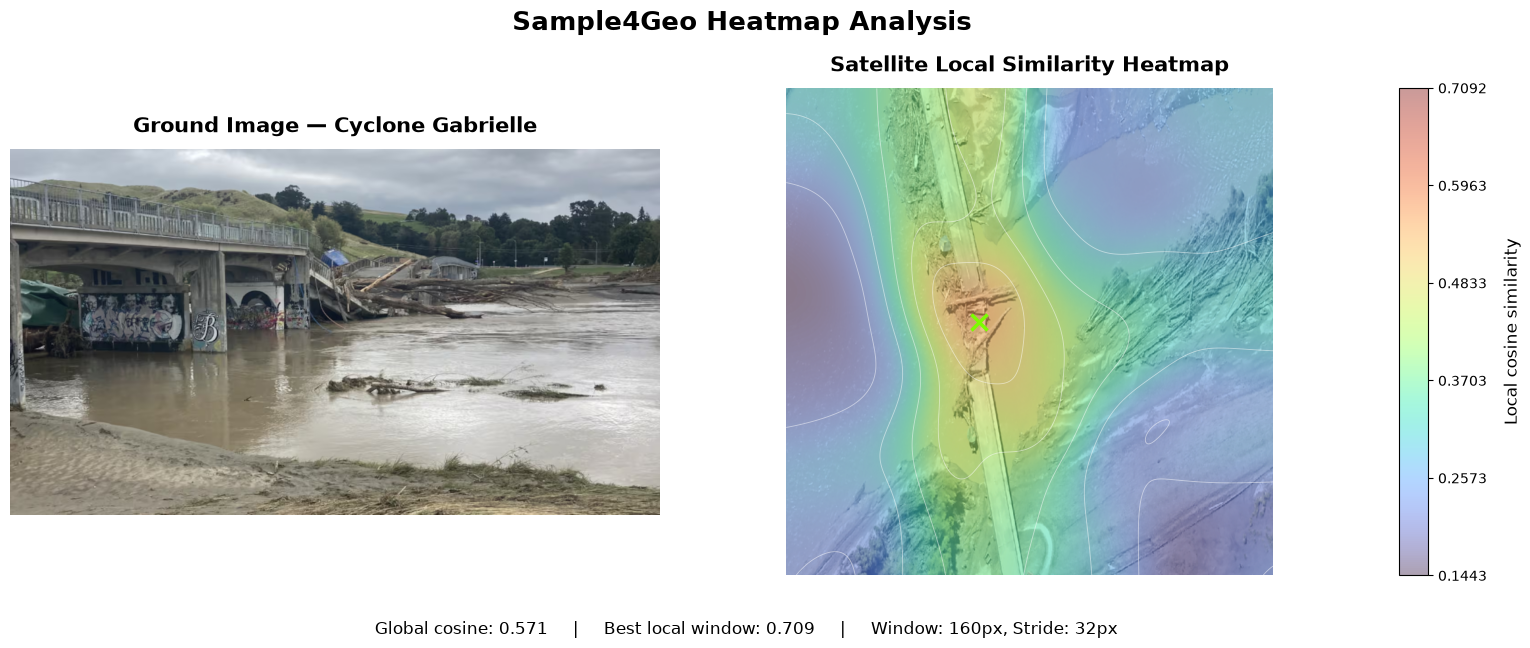

Ground: GABRIELLE_HAWKESBAY_1.png
Satellite: GABRIELLE_HAWKESBAY_SAT1.png
Global cosine: 0.5712
Best local cosine: 0.7092
Maximum patch similarity (colorbar max): 0.7092
Local score range: 0.16 to 0.5505
Total windows: 400


In [13]:

from pathlib import Path
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.ticker import MaxNLocator
from PIL import Image


# ============================================================
# 1. CONFIGURATION
# ============================================================

# Change to "panorama" or "panorama_contrastive" if needed.
# The selected model must already be loaded in `models`.
MODEL_KEY = "panorama"

GROUND_PATH = Path(
    r"E:\python_project\Geo\Test_ground_image\Cyclone"
    r"\GABRIELLE_HAWKESBAY_1.png"
)

SATELLITE_PATH = Path(
    r"E:\python_project\Geo\Test_sat_image"
    r"\GABRIELLE_HAWKESBAY_SAT1.png"
)

IMAGE_SIZE = 768

WINDOW_SIZE = 160
STRIDE = 32
BATCH_SIZE = 8

HEATMAP_ALPHA = 0.40
GAUSSIAN_SIGMA = WINDOW_SIZE / 3.5

SAVE_FIGURE = True


# ============================================================
# 2. CHECK MODEL AND IMAGES
# ============================================================

if MODEL_KEY not in models:
    raise ValueError(
        f"Model '{MODEL_KEY}' is not loaded. "
        "Enable it in ACTIVE_MODEL_KEYS and rerun "
        "the model-loading cells."
    )

model = models[MODEL_KEY]
model.eval()

for path in [GROUND_PATH, SATELLITE_PATH]:
    if not path.is_file():
        raise FileNotFoundError(path)

ground_image = Image.open(GROUND_PATH).convert("RGB")
satellite_image = Image.open(SATELLITE_PATH).convert("RGB")

satellite_display = satellite_image.resize(
    (IMAGE_SIZE, IMAGE_SIZE),
    Image.Resampling.BICUBIC
)

satellite_array = np.asarray(satellite_display)


# ============================================================
# 3. EXTRACT GLOBAL IMAGE EMBEDDINGS
# ============================================================

def prepare_image(image, transform):
    tensor = transform(
        image=np.asarray(image)
    )["image"]

    return tensor.unsqueeze(0).to(DEVICE)


with torch.inference_mode():

    ground_tensor = prepare_image(
        ground_image,
        ground_transform
    )

    satellite_tensor = prepare_image(
        satellite_image,
        sat_transform
    )

    ground_embedding = F.normalize(
        model(ground_tensor).float(),
        p=2,
        dim=1
    )

    satellite_embedding = F.normalize(
        model(satellite_tensor).float(),
        p=2,
        dim=1
    )

    global_similarity = (
        ground_embedding @ satellite_embedding.T
    ).item()


# ============================================================
# 4. GENERATE OVERLAPPING SATELLITE PATCHES
# ============================================================

def window_positions(image_size, window, stride):

    positions = list(
        range(0, image_size - window + 1, stride)
    )

    final_position = image_size - window

    if positions[-1] != final_position:
        positions.append(final_position)

    return positions


positions = window_positions(
    IMAGE_SIZE,
    WINDOW_SIZE,
    STRIDE
)

patch_coordinates = [
    (x, y)
    for y in positions
    for x in positions
]


# ============================================================
# 5. COMPUTE LOCAL COSINE SIMILARITIES
# ============================================================

local_scores = []

with torch.inference_mode():

    for start in range(
        0,
        len(patch_coordinates),
        BATCH_SIZE
    ):

        current_coordinates = patch_coordinates[
            start:start + BATCH_SIZE
        ]

        patch_tensors = []

        for x, y in current_coordinates:

            patch = satellite_display.crop(
                (
                    x,
                    y,
                    x + WINDOW_SIZE,
                    y + WINDOW_SIZE
                )
            )

            patch_tensor = sat_transform(
                image=np.asarray(patch)
            )["image"]

            patch_tensors.append(patch_tensor)

        batch = torch.stack(
            patch_tensors
        ).to(DEVICE)

        patch_embeddings = F.normalize(
            model(batch).float(),
            p=2,
            dim=1
        )

        similarities = (
            ground_embedding @ patch_embeddings.T
        ).squeeze(0)

        local_scores.extend(
            similarities.cpu().numpy().tolist()
        )

local_scores = np.asarray(local_scores)


# ============================================================
# 6. CREATE SMOOTH SPATIAL SIMILARITY FIELD
# ============================================================

yy, xx = np.mgrid[
    0:IMAGE_SIZE,
    0:IMAGE_SIZE
]

weighted_scores = np.zeros(
    (IMAGE_SIZE, IMAGE_SIZE),
    dtype=np.float64
)

weight_sum = np.zeros_like(weighted_scores)

for (x, y), score in zip(
    patch_coordinates,
    local_scores
):

    center_x = x + WINDOW_SIZE / 2
    center_y = y + WINDOW_SIZE / 2

    gaussian_weights = np.exp(
        -(
            (xx - center_x) ** 2
            + (yy - center_y) ** 2
        )
        / (2 * GAUSSIAN_SIGMA ** 2)
    )

    weighted_scores += score * gaussian_weights
    weight_sum += gaussian_weights

heatmap = weighted_scores / np.maximum(
    weight_sum,
    1e-12
)


# ============================================================
# 7. FIND HIGHEST-SIMILARITY WINDOW
# ============================================================

best_index = int(np.argmax(local_scores))

best_score = float(
    local_scores[best_index]
)

best_x, best_y = patch_coordinates[best_index]

best_center_x = best_x + WINDOW_SIZE / 2
best_center_y = best_y + WINDOW_SIZE / 2


# ============================================================
# 8. RESCALE COLORBAR TO OBSERVED COSINE VALUES
# ============================================================

local_min = float(heatmap.min())
local_max = float(heatmap.max())

# Slight padding avoids a degenerate color range.
padding = max(
    (local_max - local_min) * 0.04,
    0.005
)

# color_norm = Normalize(
#     vmin=max(-1.0, local_min - padding),
#     vmax=min(1.0, local_max + padding)
# )

color_norm = Normalize(
    vmin=max(-1.0, local_min - padding),
    vmax=best_score
)

# ============================================================
# 9. PUBLICATION-QUALITY FIGURE
# ============================================================

fig = plt.figure(
    figsize=(15.5, 6.5),
    facecolor="white"
)

gs = fig.add_gridspec(
    1,
    3,
    width_ratios=[1, 1, 0.045],
    wspace=0.10
)

ax_ground = fig.add_subplot(gs[0, 0])
ax_sat = fig.add_subplot(gs[0, 1])
ax_color = fig.add_subplot(gs[0, 2])


# Ground image
ax_ground.imshow(ground_image)
ax_ground.set_title(
    "Ground Image — Cyclone Gabrielle",
    fontsize=15,
    fontweight="bold",
    pad=12
)
ax_ground.axis("off")


# Satellite image
ax_sat.imshow(satellite_array)

overlay = ax_sat.imshow(
    heatmap,
    cmap="turbo",
    norm=color_norm,
    alpha=HEATMAP_ALPHA,
    interpolation="bilinear"
)

# Similarity contours
if local_max - local_min > 0.01:

    contour_levels = np.linspace(
        local_min,
        local_max,
        7
    )[1:-1]

    ax_sat.contour(
        heatmap,
        levels=contour_levels,
        colors="white",
        linewidths=0.65,
        alpha=0.48
    )


# Mark highest-similarity window center
ax_sat.plot(
    best_center_x,
    best_center_y,
    marker="x",
    color="#7CFC00",
    markersize=12,
    markeredgewidth=2.5
)

ax_sat.set_title(
    "Satellite Local Similarity Heatmap",
    fontsize=15,
    fontweight="bold",
    pad=12
)

ax_sat.axis("off")


# Correctly scaled colorbar
cbar = fig.colorbar(
    overlay,
    cax=ax_color
)

cbar.set_ticks(
    np.linspace(color_norm.vmin, color_norm.vmax, 6)
)

cbar.ax.set_ylim(
    color_norm.vmin,
    color_norm.vmax
)

cbar.set_label(
    "Local cosine similarity",
    fontsize=12,
    labelpad=12
)

cbar.ax.tick_params(labelsize=10)


# Main title
fig.suptitle(
    f"Sample4Geo Heatmap Analysis ",
    fontsize=19,
    fontweight="bold",
    y=0.99
)

fig.text(
    0.5,
    0.03,
    (
        f"Global cosine: {global_similarity:.3f}"
        f"     |     Best local window: {best_score:.3f}"
        f"     |     Window: {WINDOW_SIZE}px, Stride: {STRIDE}px"
    ),
    ha="center",
    fontsize=12
)

fig.subplots_adjust(
    left=0.025,
    right=0.94,
    top=0.87,
    bottom=0.12
)

if SAVE_FIGURE:

    output_path = (
        SATELLITE_PATH.parent
        / "Gabrielle_Sample4Geo_Heatmap.png"
    )

    fig.savefig(
        output_path,
        dpi=600,
        bbox_inches="tight"
    )

plt.rcParams["figure.dpi"] = 180

plt.show()


print("Ground:", GROUND_PATH.name)
print("Satellite:", SATELLITE_PATH.name)
print("Global cosine:", round(global_similarity, 4))
print("Best local cosine:", round(best_score, 4))
print("Maximum patch similarity (colorbar max):", round(best_score, 4))
print("Local score range:", round(local_min, 4), "to", round(local_max, 4))
print("Total windows:", len(patch_coordinates))

The model generates a similarity score between a ground image and a satellite image. The stronger the similarity between them, the higher the score.”